# Classificador Vizinho Mais Próximo (1-NN)

*Implementação com scikit-learn · base processada (sem duplicatas, z-score)*

Cada amostra de teste recebe a classe da amostra de treino mais próxima segundo a distância de Minkowski de ordem $m$:

$$d_m(\mathbf{x}, \mathbf{z}) = \Big(\sum_{k} |x_k - z_k|^m\Big)^{1/m}, \qquad m \in \{1/2,\ 2/3,\ 1,\ 3/2,\ 2,\ 5/2\}$$

Para $m < 1$, $d_m$ não satisfaz a desigualdade triangular (não é métrica), mas continua definindo um critério de proximidade.

Protocolo (OBS 1–4 do enunciado): 100 rodadas treino-teste independentes e estratificadas para cada separação 20/80, 30/70, 50/50, 70/30 e 80/20.

## Dados

In [1]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"  # antes do numpy: evita falta de memória do OpenBLAS no Windows

import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
from avaliacao import (SPLITS, carregar, avaliar, estatisticas, matrizes_confusao, grafico_splits,
                       por_classe, grafico_por_classe, resumo, salvar)

pd.set_option("display.max_rows", 200)

X, y, classes = carregar(processada=True)
print(f"{len(y)} instâncias | {X.shape[1]} atributos | {len(classes)} classes: {list(classes)}")

5406 instâncias | 4 atributos | 4 classes: ['Move-Forward', 'Sharp-Right-Turn', 'Slight-Left-Turn', 'Slight-Right-Turn']


## Modelo

In [2]:
import warnings
from sklearn.neighbors import KNeighborsClassifier

# para m < 1 o scikit-learn avisa que a distância não é métrica e usa busca por força bruta
warnings.filterwarnings("ignore", message="Mind that for 0 < p < 1")

ORDENS = {"1/2": 1/2, "2/3": 2/3, "1": 1, "3/2": 3/2, "2": 2, "5/2": 5/2}
MODELOS = {f"m = {nome}": KNeighborsClassifier(n_neighbors=1, p=m, algorithm="brute") for nome, m in ORDENS.items()}

## Execução
100 rodadas × 5 separações. Em cada rodada, todos os modelos usam a mesma divisão treino/teste.

In [3]:
res, confusoes = avaliar(MODELOS, X, y, classes)
salvar(res, "classification_sklearn", "vizinho_mais_prox")

## OBS 1 e 2 — Estatísticas de acurácia e tempos de treinamento/teste (ms)

In [4]:
estatisticas(res).round(4)

média  desvio  máxima  mínima  mediana  t_treino_ms  \
split modelo                                                          
20/80 m = 1/2  0.9489  0.0043  0.9579  0.9350   0.9487       1.2101   
      m = 2/3  0.9498  0.0045  0.9579  0.9355   0.9500       1.1062   
      m = 1    0.9507  0.0048  0.9595  0.9336   0.9510       1.1018   
      m = 3/2  0.9500  0.0048  0.9584  0.9332   0.9506       1.0855   
      m = 2    0.9489  0.0048  0.9588  0.9334   0.9494       1.0669   
      m = 5/2  0.9481  0.0049  0.9577  0.9336   0.9483       1.1011   
30/70 m = 1/2  0.9585  0.0037  0.9670  0.9469   0.9588       1.0097   
      m = 2/3  0.9594  0.0037  0.9678  0.9466   0.9594       1.0332   
      m = 1    0.9596  0.0034  0.9675  0.9479   0.9600       1.0349   
      m = 3/2  0.9592  0.0035  0.9667  0.9493   0.9594       0.9788   
      m = 2    0.9582  0.0036  0.9651  0.9474   0.9588       0.9737   
      m = 5/2  0.9577  0.0036  0.9643  0.9469   0.9584       0.9909   
50/50 m = 1/2  0.9672  0.0031  0.9745  0.9578   0.9671       1.0791   
      m = 2/3  0.9682  0.0031  0.9748  0.9612   0.9680       1.1270   
      m = 1    0.9678  0.0032  0.9756  0.9597   0.9682       1.0445   
      m = 3/2  0.9677  0.0034  0.9771  0.9597   0.9678       1.0694   
      m = 2    0.9670  0.0033  0.9748  0.9593   0.9674       1.0474   
      m = 5/2  0.9666  0.0032  0.9741  0.9589   0.9671       1.0640   
70/30 m = 1/2  0.9721  0.0035  0.9797  0.9636   0.9716       1.0606   
      m = 2/3  0.9733  0.0035  0.9809  0.9655   0.9729       1.1071   
      m = 1    0.9726  0.0036  0.9815  0.9649   0.9723       1.0528   
      m = 3/2  0.9727  0.0035  0.9803  0.9655   0.9729       1.0337   
      m = 2    0.9723  0.0037  0.9815  0.9642   0.9723       1.0642   
      m = 5/2  0.9721  0.0037  0.9809  0.9649   0.9723       1.0729   
80/20 m = 1/2  0.9730  0.0040  0.9824  0.9584   0.9732       1.0424   
      m = 2/3  0.9737  0.0038  0.9852  0.9630   0.9741       1.0885   
      m = 1    0.9730  0.0042  0.9861  0.9603   0.9732       1.0654   
      m = 3/2  0.9729  0.0043  0.9843  0.9603   0.9723       1.0323   
      m = 2    0.9725  0.0046  0.9824  0.9593   0.9723       1.0519   
      m = 5/2  0.9725  0.0045  0.9824  0.9603   0.9732       1.1368   

               t_teste_ms  
split modelo               
20/80 m = 1/2     89.3545  
      m = 2/3     87.8332  
      m = 1       10.0805  
      m = 3/2     87.7089  
      m = 2        6.0852  
      m = 5/2     87.2157  
30/70 m = 1/2     91.6809  
      m = 2/3     92.5946  
      m = 1       10.6713  
      m = 3/2     91.6642  
      m = 2        6.2023  
      m = 5/2     92.0981  
50/50 m = 1/2    146.3621  
      m = 2/3    147.5115  
      m = 1       16.0314  
      m = 3/2    146.1514  
      m = 2       10.4622  
      m = 5/2    145.3029  
70/30 m = 1/2    101.6505  
      m = 2/3    101.8779  
      m = 1       11.4522  
      m = 3/2    101.8695  
      m = 2        9.2218  
      m = 5/2    101.7361  
80/20 m = 1/2    105.9732  
      m = 2/3    106.1762  
      m = 1       12.0814  
      m = 3/2    104.9914  
      m = 2        8.3508  
      m = 5/2    105.6840

## OBS 2 — Matrizes de confusão da melhor e da pior rodada

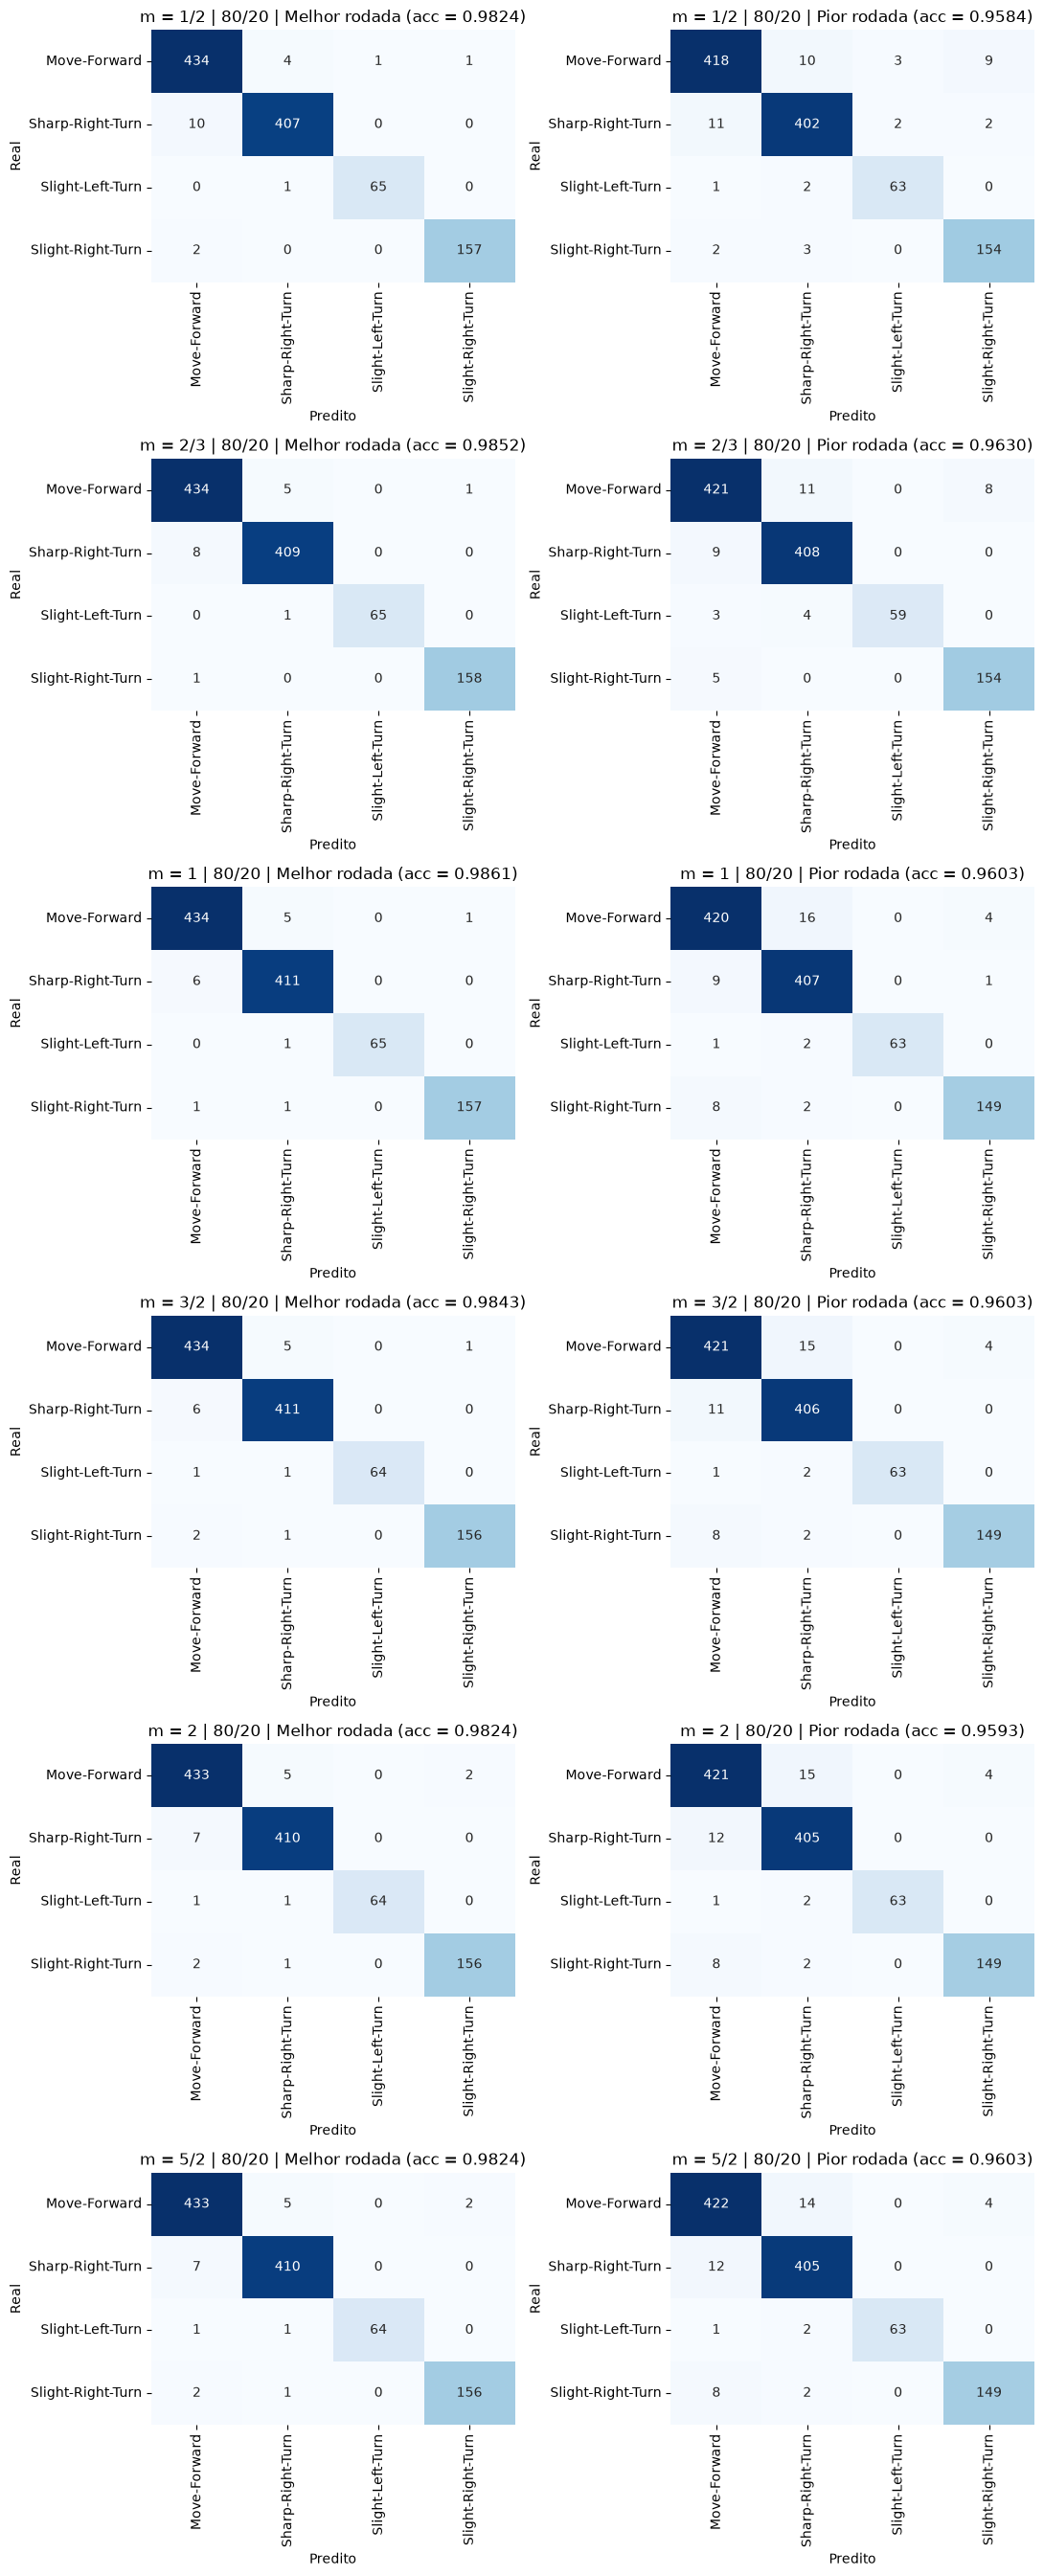

In [5]:
matrizes_confusao(res, confusoes, classes, splits=["80/20"])

## OBS 3 — Efeito da separação treino/teste

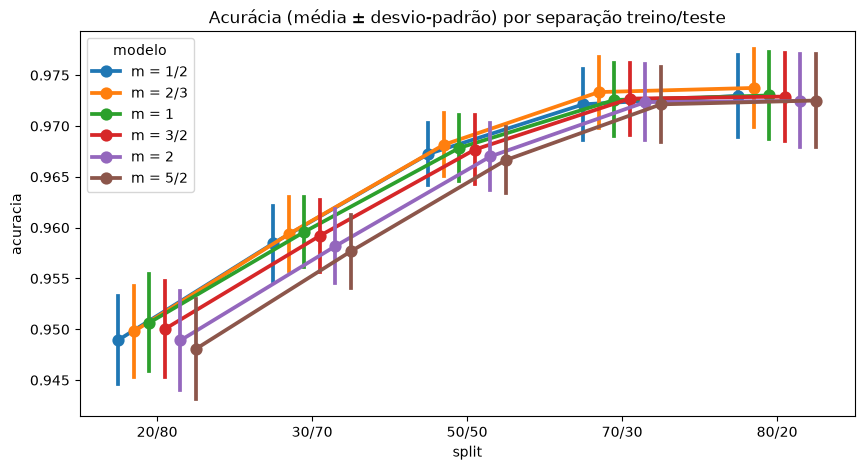

In [6]:
grafico_splits(res)

## OBS 4 — Desempenho por classe (taxa de acerto de cada classe)

In [7]:
por_classe(res, classes).round(4)

média  desvio  máxima  mínima  mediana
classe            split modelo                                          
Move-Forward      20/80 m = 1/2  0.9414  0.0081  0.9603  0.9205   0.9421
                        m = 2/3  0.9427  0.0084  0.9614  0.9154   0.9427
                        m = 1    0.9442  0.0086  0.9625  0.9115   0.9449
                        m = 3/2  0.9444  0.0085  0.9637  0.9171   0.9452
                        m = 2    0.9438  0.0087  0.9642  0.9177   0.9447
                        m = 5/2  0.9433  0.0087  0.9631  0.9217   0.9435
                  30/70 m = 1/2  0.9530  0.0068  0.9701  0.9377   0.9526
                        m = 2/3  0.9544  0.0069  0.9695  0.9351   0.9543
                        m = 1    0.9552  0.0071  0.9721  0.9338   0.9552
                        m = 3/2  0.9551  0.0071  0.9740  0.9351   0.9559
                        m = 2    0.9544  0.0073  0.9721  0.9358   0.9549
                        m = 5/2  0.9538  0.0073  0.9721  0.9338   0.9546
                  50/50 m = 1/2  0.9629  0.0058  0.9755  0.9473   0.9637
                        m = 2/3  0.9641  0.0058  0.9800  0.9500   0.9646
                        m = 1    0.9637  0.0059  0.9782  0.9464   0.9637
                        m = 3/2  0.9639  0.0061  0.9818  0.9455   0.9637
                        m = 2    0.9637  0.0060  0.9818  0.9464   0.9637
                        m = 5/2  0.9631  0.0062  0.9809  0.9455   0.9628
                  70/30 m = 1/2  0.9685  0.0067  0.9894  0.9546   0.9682
                        m = 2/3  0.9703  0.0065  0.9894  0.9546   0.9697
                        m = 1    0.9696  0.0069  0.9894  0.9531   0.9697
                        m = 3/2  0.9695  0.0067  0.9894  0.9546   0.9682
                        m = 2    0.9697  0.0066  0.9879  0.9546   0.9697
                        m = 5/2  0.9692  0.0065  0.9864  0.9531   0.9697
                  80/20 m = 1/2  0.9688  0.0075  0.9864  0.9500   0.9693
                        m = 2/3  0.9700  0.0078  0.9864  0.9500   0.9705
                        m = 1    0.9693  0.0078  0.9864  0.9523   0.9705
                        m = 3/2  0.9694  0.0080  0.9886  0.9500   0.9705
                        m = 2    0.9698  0.0080  0.9886  0.9500   0.9705
                        m = 5/2  0.9696  0.0080  0.9886  0.9500   0.9705
Sharp-Right-Turn  20/80 m = 1/2  0.9663  0.0068  0.9784  0.9442   0.9658
                        m = 2/3  0.9677  0.0069  0.9814  0.9418   0.9682
                        m = 1    0.9690  0.0071  0.9820  0.9418   0.9700
                        m = 3/2  0.9678  0.0071  0.9814  0.9436   0.9685
                        m = 2    0.9660  0.0073  0.9790  0.9436   0.9667
                        m = 5/2  0.9647  0.0079  0.9778  0.9436   0.9658
                  30/70 m = 1/2  0.9711  0.0066  0.9849  0.9534   0.9722
                        m = 2/3  0.9731  0.0064  0.9863  0.9568   0.9739
                        m = 1    0.9737  0.0065  0.9877  0.9575   0.9746
                        m = 3/2  0.9731  0.0059  0.9870  0.9602   0.9739
                        m = 2    0.9720  0.0058  0.9856  0.9575   0.9726
                        m = 5/2  0.9717  0.0058  0.9863  0.9575   0.9719
                  50/50 m = 1/2  0.9774  0.0055  0.9904  0.9606   0.9774
                        m = 2/3  0.9788  0.0055  0.9923  0.9645   0.9789
                        m = 1    0.9789  0.0056  0.9923  0.9654   0.9789
                        m = 3/2  0.9785  0.0058  0.9904  0.9625   0.9789
                        m = 2    0.9776  0.0056  0.9885  0.9635   0.9784
                        m = 5/2  0.9775  0.0052  0.9875  0.9645   0.9779
                  70/30 m = 1/2  0.9816  0.0057  0.9936  0.9648   0.9808
                        m = 2/3  0.9825  0.0053  0.9968  0.9696   0.9832
                        m = 1    0.9816  0.0051  0.9936  0.9696   0.9824
                        m = 3/2  0.9821  0.0049  0.9952  0.9712   0.9824
                        m = 2    0.9815  0.0050  0.9968  0.9696   0.9808
                   

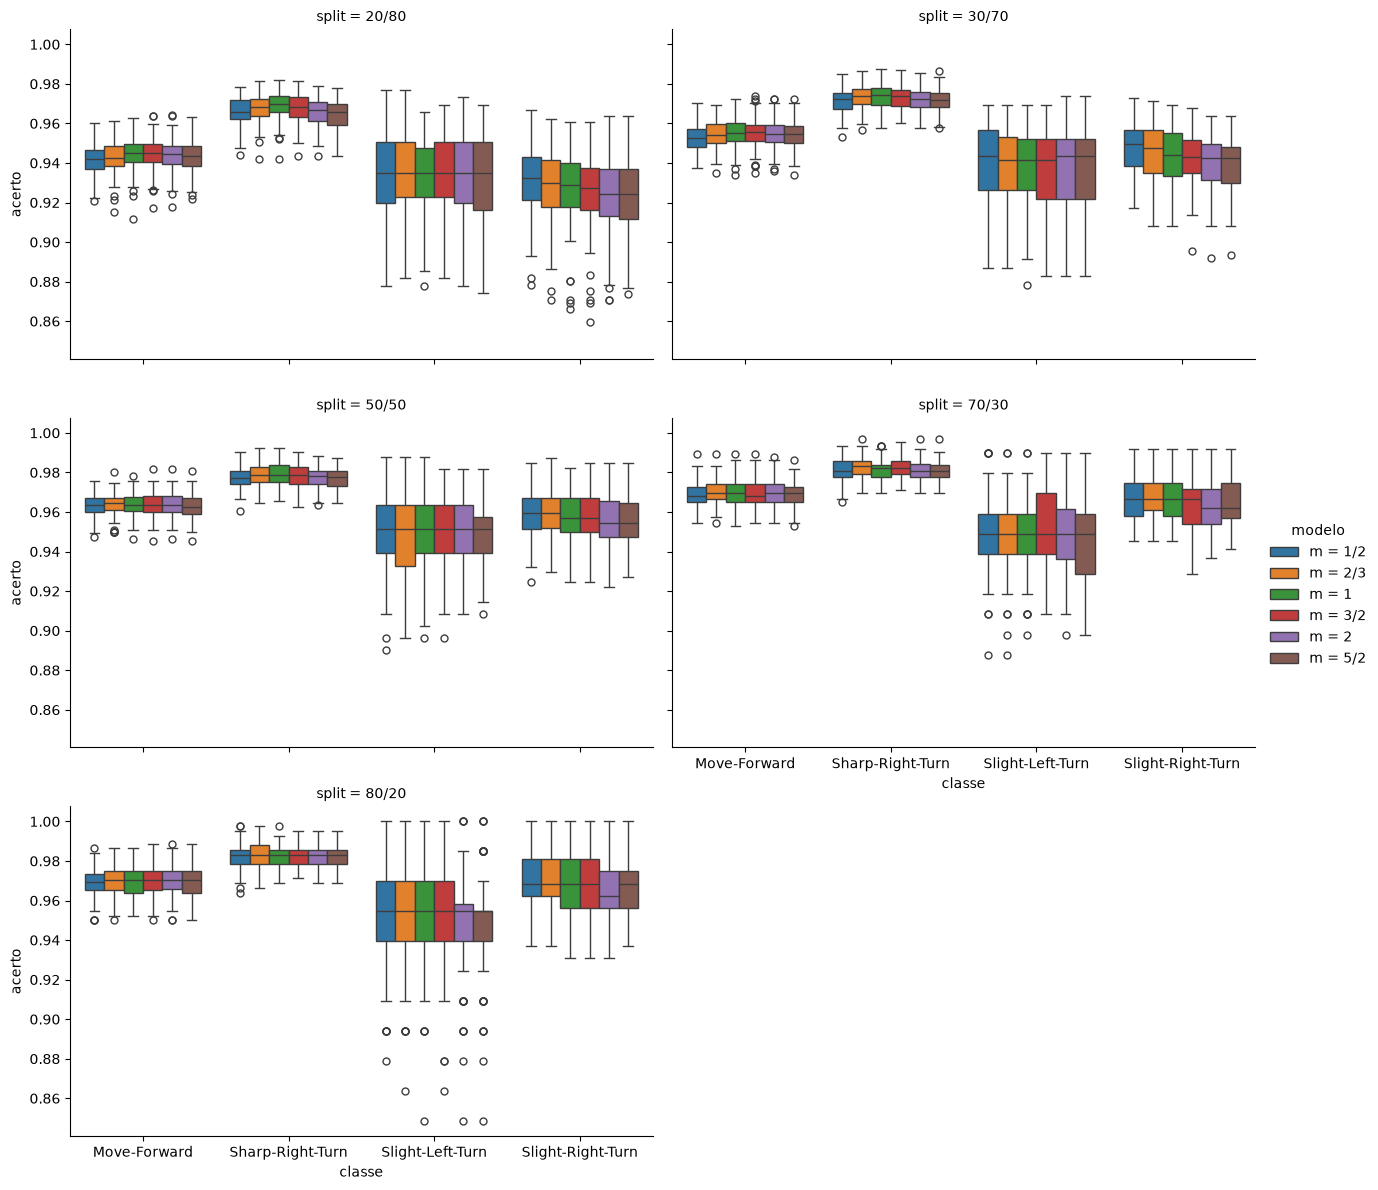

In [8]:
grafico_por_classe(res, classes)

## Resumo dos resultados

In [9]:
resumo(res, classes)

Melhor configuração: m = 2/3 com split 80/20 -> acurácia média 0.9737

Tempo médio por rodada (ms):
  m = 1/2: treino 1.080 | teste 107.004
  m = 2/3: treino 1.092 | teste 107.199
  m = 1: treino 1.060 | teste 12.063
  m = 3/2: treino 1.040 | teste 106.477
  m = 2: treino 1.041 | teste 8.064
  m = 5/2: treino 1.073 | teste 106.407

Efeito do split (acurácia média 20/80 -> 80/20):
  m = 1/2: 0.9489 -> 0.9730 (+0.0240)
  m = 2/3: 0.9498 -> 0.9737 (+0.0240)
  m = 1: 0.9507 -> 0.9730 (+0.0223)
  m = 3/2: 0.9500 -> 0.9729 (+0.0229)
  m = 2: 0.9489 -> 0.9725 (+0.0236)
  m = 5/2: 0.9481 -> 0.9725 (+0.0244)

Taxa de acerto média por classe (todas as rodadas):
  Slight-Left-Turn: 0.9445
  Slight-Right-Turn: 0.9521
  Move-Forward: 0.9600
  Sharp-Right-Turn: 0.9763
Classe mais fácil: Sharp-Right-Turn | mais difícil: Slight-Left-Turn
